# Rental bikes count prediction: Dataset EDA

### Goal
We predict the **hourly total number of rented bikes (`cnt`)** in the Capital
Bikeshare system (Washington, D.C., 2011-2012) from calendar and weather
features of the same hour. `cnt` is the sum of casual and registered users.

**Why it matters.** Operators need demand estimates to decide how many bikes
to place at stations and when to rebalance them.

**Research question.** How much does random k-fold cross-validation
overestimate the accuracy of hourly demand predictions compared with
chronological validation, and does this gap depend on the type of model?

### What this notebook does
Inspects the size and types of the data, missing values, the distribution of
the target, the time structure (gaps, ordering), relationships between the
features and the target, and possible leakage. It ends with a table of
decisions on what to keep, drop or encode, and why.

### Data
Fanaee-T, H. (2013). *Bike Sharing* [Dataset]. UCI Machine Learning
Repository. https://doi.org/10.24432/C5W894 (CC BY 4.0).

## 1 - Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
PATH = "data/hour.csv"

In [2]:
df = pd.read_csv(PATH)
print(df.shape)

(17379, 17)


## 2 - Overview

In [3]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [4]:
df.tail()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
17374,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
17375,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
17376,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90
17377,17378,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,13,48,61
17378,17379,2012-12-31,1,1,12,23,0,1,1,1,0.26,0.2727,0.65,0.1343,12,37,49


In [5]:
df.sample(5)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
11010,11011,2012-04-08,2,1,4,22,0,0,0,1,0.50,0.4848,0.36,0.2239,33,85,118
8214,8215,2011-12-13,4,0,12,22,0,2,1,1,0.30,0.3030,0.52,0.1642,5,102,107
9650,9651,2012-02-12,1,1,2,1,0,0,0,3,0.08,0.0455,0.79,0.4627,0,24,24
157,158,2011-01-07,1,0,1,20,0,5,1,1,0.18,0.2121,0.47,0.1045,1,50,51
7773,7774,2011-11-25,4,0,11,12,0,5,1,1,0.46,0.4545,0.51,0.1045,126,146,272


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


In [7]:
print(df.isna().sum())
print("duplicate rows:", df.duplicated().sum())

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
duplicate rows: 0


## Time structure

In [8]:
df["dteday"] = pd.to_datetime(df["dteday"])
ts = df["dteday"] + pd.to_timedelta(df["hr"], unit="h")

print("instant increasing:", df["instant"].is_monotonic_increasing)
print("timestamps increasing:", ts.is_monotonic_increasing)
print("timestamps unique:", ts.is_unique)

instant increasing: True
timestamps increasing: True
timestamps unique: True


In [9]:
print((df["casual"] + df["registered"] == df["cnt"]).all())

True


In [10]:
df["ts"] = df["dteday"] + pd.to_timedelta(df["hr"], unit="h")

In [11]:
full_index = pd.date_range(df["ts"].min(), df["ts"].max(), freq="h")
missing = full_index.difference(pd.DatetimeIndex(df["ts"]))

print("expected hours:", len(full_index))
print("rows in data:  ", len(df))
print("missing hours: ", len(missing))

expected hours: 17544
rows in data:   17379
missing hours:  165


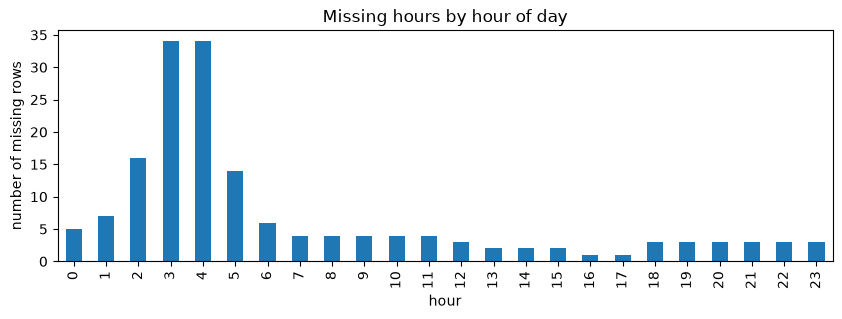

In [12]:
missing_by_hour = pd.Series(missing.hour).value_counts().sort_index()
missing_by_hour.plot(kind="bar", figsize=(10, 3), title="Missing hours by hour of day")
plt.xlabel("hour")
plt.ylabel("number of missing rows")
plt.show()

In [13]:
print(pd.Series(missing.date).value_counts().head(10))

2012-10-29    23
2011-01-27    16
2012-10-30    13
2011-01-18    12
2011-01-26     8
2011-08-28     7
2011-02-22     6
2011-08-27     6
2011-01-03     2
2011-01-11     2
Name: count, dtype: int64


## Target analysis

In [14]:
print(df["cnt"].describe())
print("skew:", df["cnt"].skew())
print("variance / mean:", df["cnt"].var() / df["cnt"].mean())

count    17379.000000
mean       189.463088
std        181.387599
min          1.000000
25%         40.000000
50%        142.000000
75%        281.000000
max        977.000000
Name: cnt, dtype: float64
skew: 1.277411603749058
variance / mean: 173.65631224052566


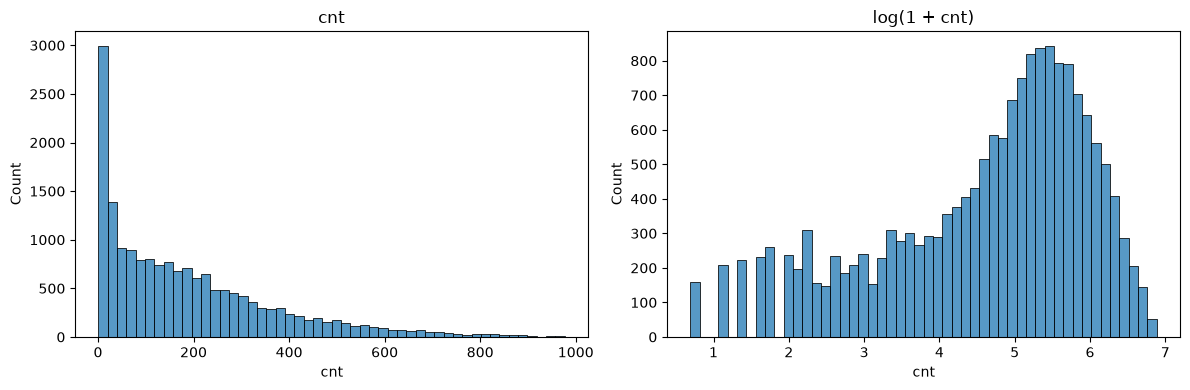

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["cnt"], bins=50, ax=axes[0])
axes[0].set_title("cnt")

sns.histplot(np.log1p(df["cnt"]), bins=50, ax=axes[1])
axes[1].set_title("log(1 + cnt)")

plt.tight_layout()
plt.savefig("figures/cnt_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Target distribution.** `cnt` is strongly right-skewed: many hours with very
low demand (mostly night) and a long tail up to ~970. A log transform does not
make it normal either (left tail of low values), which reflects a mixture of
night and day regimes. The minimum is 1, so hours with zero rentals are
absent from the file. Implication: errors will be dominated by high-demand
hours, so we report both MAE and RMSE; whether to model log(cnt) or use a
count loss (Poisson) is a modelling decision tested later.

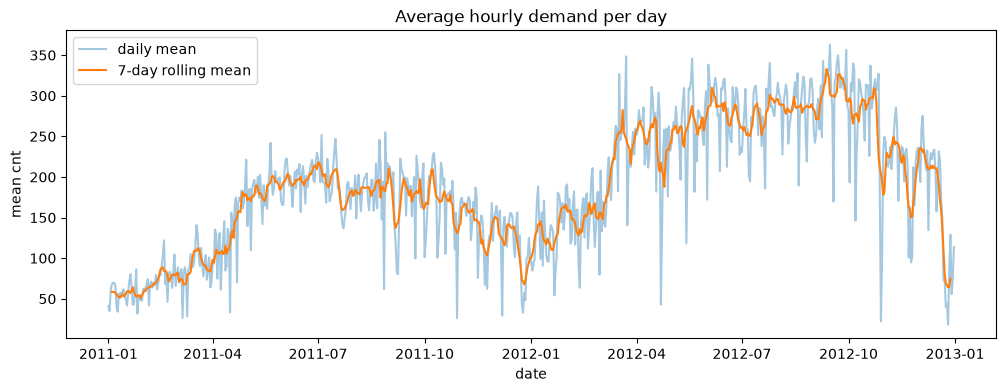

In [16]:
daily = df.set_index("ts")["cnt"].resample("D").mean()

plt.figure(figsize=(12, 4))
plt.plot(daily.index, daily.values, alpha=0.4, label="daily mean")
plt.plot(daily.index, daily.rolling(7, center=True).mean(), label="7-day rolling mean")
plt.title("Average hourly demand per day")
plt.xlabel("date")
plt.ylabel("mean cnt")
plt.legend()
plt.savefig("figures/daily_mean_cnt.png", dpi=150, bbox_inches="tight")
plt.show()

**Demand over time.** The 7-day mean shows seasonality plus a clear upward
level shift in 2012. There are sharp one-off drops (late August 2011, late
October 2012) that look like extreme weather events. Implication: the data
are not stationary, so a random split lets the model see days from the same
season and level on both sides of the split, while a chronological split
forces it to predict a higher-demand year from a lower-demand one. This is
the core of our research question.

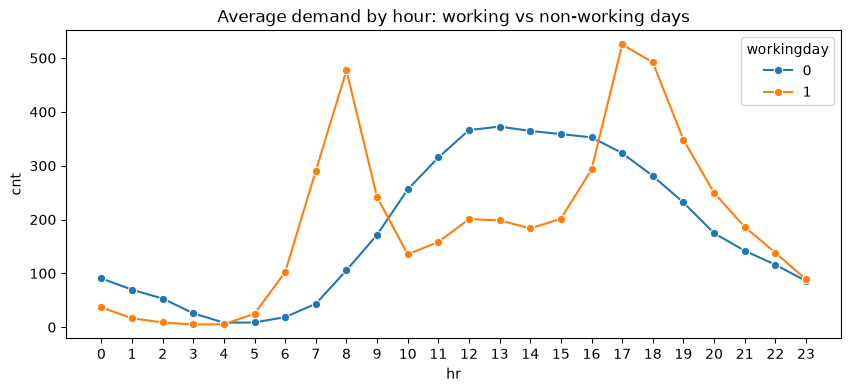

In [17]:
profile = df.groupby(["workingday", "hr"])["cnt"].mean().reset_index()

plt.figure(figsize=(10, 4))
sns.lineplot(data=profile, x="hr", y="cnt", hue="workingday", marker="o")
plt.title("Average demand by hour: working vs non-working days")
plt.xticks(range(0, 24))
plt.savefig("figures/hourly_profile.png", dpi=150, bbox_inches="tight")
plt.show()

**Daily profile.** The shape of the daily cycle depends strongly on the type
of day: working days have two commuting peaks (~08:00 and ~17-18:00), while
non-working days have one broad midday peak. Implication: `hr` has a
non-linear, cyclical effect and interacts with `workingday`. A linear model
with a single coefficient per feature cannot represent this (it needs one-hot
hours and interaction terms), whereas tree-based models can learn it directly.
This is the main argument for comparing linear and tree-based models.

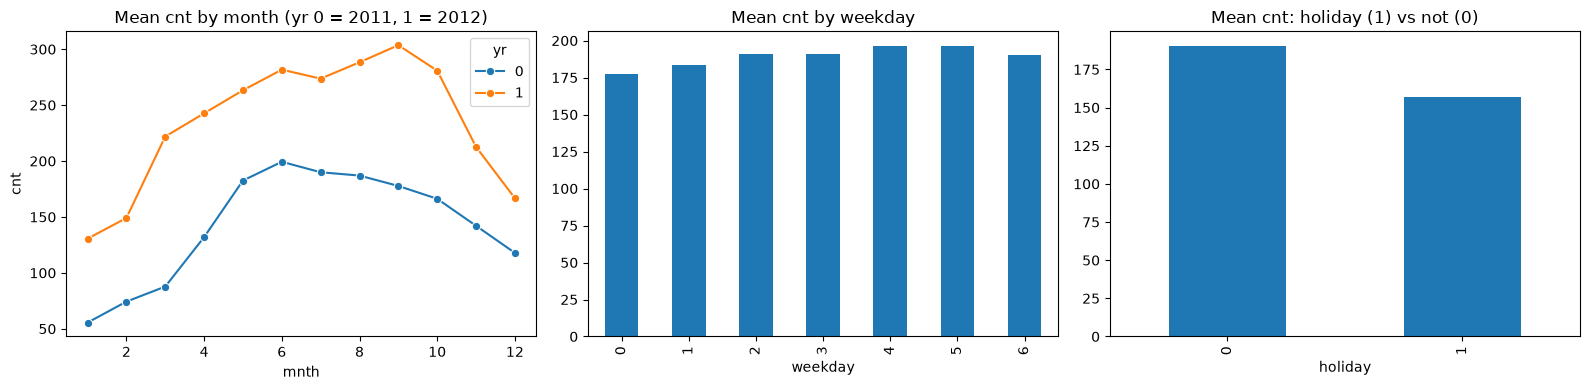

In [18]:
monthly = df.groupby(["yr", "mnth"])["cnt"].mean().reset_index()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.lineplot(data=monthly, x="mnth", y="cnt", hue="yr", marker="o", ax=axes[0])
axes[0].set_title("Mean cnt by month (yr 0 = 2011, 1 = 2012)")

df.groupby("weekday")["cnt"].mean().plot(kind="bar", ax=axes[1], title="Mean cnt by weekday")

df.groupby("holiday")["cnt"].mean().plot(kind="bar", ax=axes[2], title="Mean cnt: holiday (1) vs not (0)")

plt.tight_layout()
plt.savefig("figures/calendar_effects.png", dpi=150, bbox_inches="tight")
plt.show()

**Calendar effects.** Demand has a clear seasonal cycle (low in winter, high
in summer/autumn), and 2012 is higher than 2011 in every month (e.g. January
~130 vs ~55 rentals/hour), so the system grew between the two years. The
weekday alone has a weak effect (means ~177-196), while holidays reduce
demand (~157 vs ~190). Implication: `yr` carries a level shift that a model
trained on 2011 cannot extrapolate to 2012; this matters for the
chronological validation and must be discussed in the limitations.

In [19]:
print(df["weathersit"].value_counts().sort_index())

weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64


## Weather effects

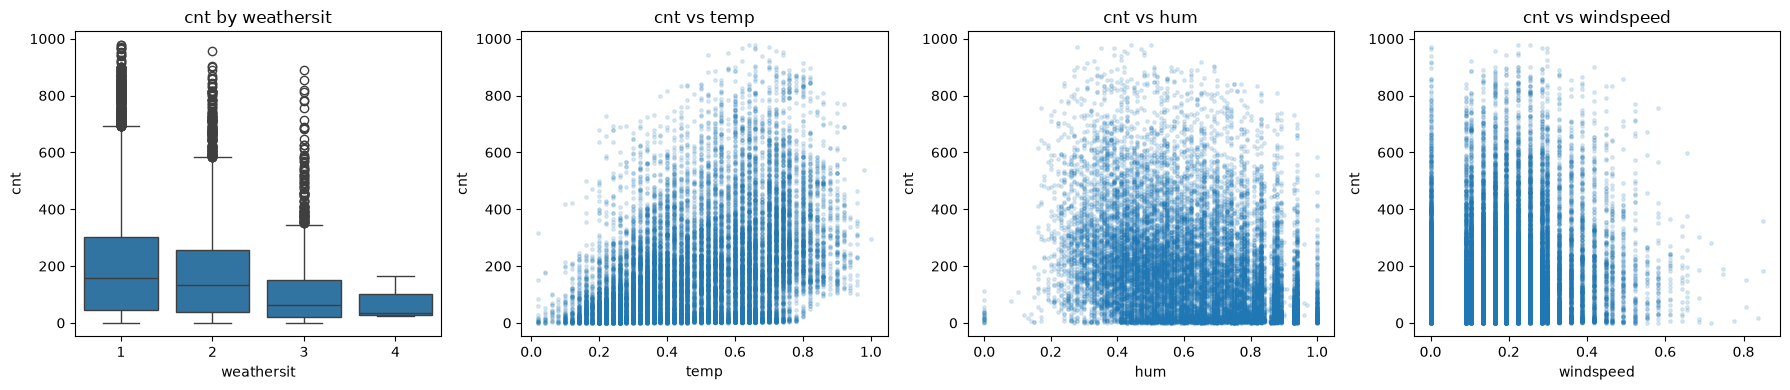

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

sns.boxplot(data=df, x="weathersit", y="cnt", ax=axes[0])
axes[0].set_title("cnt by weathersit")

for ax, col in zip(axes[1:], ["temp", "hum", "windspeed"]):
    ax.scatter(df[col], df["cnt"], s=6, alpha=0.15)
    ax.set_xlabel(col)
    ax.set_ylabel("cnt")
    ax.set_title(f"cnt vs {col}")

plt.tight_layout()
plt.savefig("figures/weather_effects.png", dpi=150, bbox_inches="tight")
plt.show()

**Weather effects.** Demand falls as weather worsens (median ~160 for clear
weather vs ~65 for light rain/snow), and category 4 has almost no
observations. Temperature has a non-monotonic effect: demand grows up to
about 0.8 (~30 °C) and the upper envelope decreases afterwards. Humidity
and wind speed have weaker, downward-sloping envelopes. The large spread at
every x value shows that weather alone explains little; the hour of day
dominates. Suspicious values: a block of `windspeed == 0` separated from
the next value by a gap and a few `hum == 0` rows look like missing
measurements encoded as zeros. Implication: `weathersit == 4` cannot be
reliably estimated, and zero wind speed should be treated with care.

In [21]:
print("windspeed == 0:", (df["windspeed"] == 0).sum())
print("hum == 0:      ", (df["hum"] == 0).sum())
print(df["windspeed"].value_counts().sort_index().head(5))

windspeed == 0: 2180
hum == 0:       22
windspeed
0.0000    2180
0.0896    1425
0.1045    1617
0.1343    1738
0.1642    1695
Name: count, dtype: int64


In [22]:
zero_wind = df["windspeed"] == 0

print(zero_wind.groupby(df["yr"]).mean())
print(zero_wind.groupby(df["hr"]).mean().round(3))

yr
0    0.128051
1    0.122853
Name: windspeed, dtype: float64
hr
0     0.158
1     0.169
2     0.193
3     0.185
4     0.159
5     0.170
6     0.160
7     0.150
8     0.142
9     0.142
10    0.117
11    0.098
12    0.120
13    0.108
14    0.080
15    0.099
16    0.075
17    0.079
18    0.056
19    0.073
20    0.085
21    0.120
22    0.140
23    0.140
Name: windspeed, dtype: float64


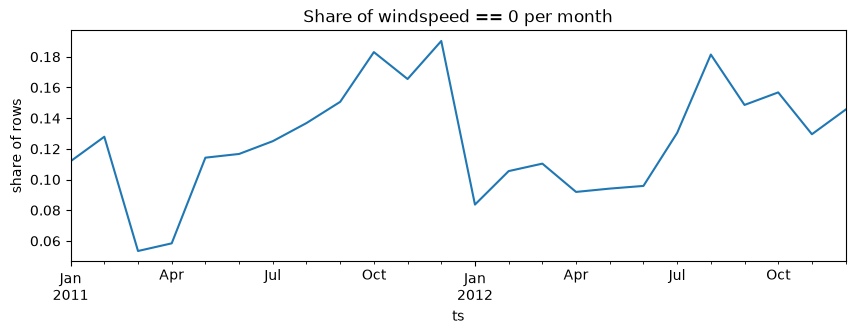

In [23]:
share = zero_wind.groupby(df["ts"].dt.to_period("M")).mean()

share.plot(figsize=(10, 3), title="Share of windspeed == 0 per month")
plt.ylabel("share of rows")
plt.show()

In [24]:
smallest_values = np.sort(df["windspeed"].unique())[:4]
subset = df[df["windspeed"].isin(smallest_values)]

print(subset.groupby("windspeed")["cnt"].agg(["count", "mean", "median"]))

           count        mean  median
windspeed                           
0.0000      2180  160.643578   107.0
0.0896      1425  150.037895    99.0
0.1045      1617  166.246753   111.0
0.1343      1738  176.307825   130.0


**Zero wind speed.** `windspeed == 0` occurs in 2,180 rows (12.5%) with a
similar share in 2011 and 2012 (12.8% vs 12.3%), without a persistent break
over time. Zeros are more frequent at night (up to ~19% at 02:00) than in the
afternoon (5-8% at 16-18:00), as expected for genuinely calmer air. Mean
demand at zero wind (160.6) is similar to that at the next smallest values
(150-176). The smallest non-zero value is ~6 in the original units, so
readings of 1-5 never occur; zero probably means "below the sensor
threshold". Decision: keep `windspeed` unchanged, with no indicator feature.

In [25]:
print(df.loc[df["hum"] == 0, "dteday"].dt.date.value_counts().sort_index())

dteday
2011-03-10    22
Name: count, dtype: int64


**Zero humidity.** All 22 rows with `hum == 0` fall on a single day
(2011-03-10), so they are a sensor failure for that day rather than random
noise (humidity cannot be zero). Decision: mark these values as missing and
impute them with the training-fold median inside each model's pipeline, so
that no information from validation or test data is used.

## Correlations

In [26]:
series = df.set_index("ts")["cnt"].reindex(full_index)

for lag in [1, 24, 168]:
    print(f"lag {lag:>3} h: {series.autocorr(lag=lag):.3f}")

lag   1 h: 0.843
lag  24 h: 0.819
lag 168 h: 0.876


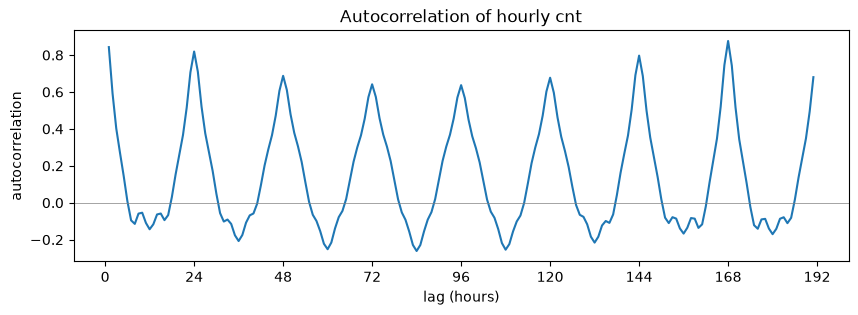

In [27]:
lags = range(1, 24 * 8)
acf = [series.autocorr(lag=l) for l in lags]

plt.figure(figsize=(10, 3))
plt.plot(lags, acf)
plt.axhline(0, color="grey", lw=0.5)
plt.xticks(range(0, 24 * 8 + 1, 24))
plt.xlabel("lag (hours)")
plt.ylabel("autocorrelation")
plt.title("Autocorrelation of hourly cnt")
plt.savefig("figures/cnt_autocorrelation.png", dpi=150, bbox_inches="tight")
plt.show()

**Autocorrelation.** Hourly demand is strongly autocorrelated: 0.84 at lag
1 h, 0.82 at lag 24 h and 0.88 at lag 168 h, with peaks at multiples of 24
hours, so adjacent hours and the same hour on previous days and weeks are
very similar. Implication: with random k-fold cross-validation most
validation hours have near-identical neighbours in the training set, so we
expect optimistic estimates; chronological validation removes this. Part of
this autocorrelation is the regular daily and weekly cycle that the calendar
features can also capture, so the correlation motivates the comparison but
does not prove the size of the gap; this is measured experimentally. We do
not use past demand as a feature, which is a limitation: lagged demand (e.g.
one week earlier) would likely improve accuracy considerably.

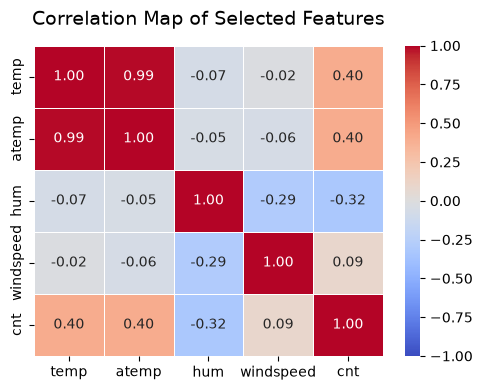

In [28]:
plt.figure(figsize=(5,4))
features = ['temp', 'atemp', 'hum', 'windspeed', 'cnt']
corr_subset = df[features]
corr_matrix = corr_subset.corr()
sns.heatmap(
    corr_matrix,
    annot=True,  # Displays the correlation value in each cell
    cmap="coolwarm",  # Diverging color palette (blue = negative, red = positive)
    vmin=-1,  # Forces scale minimum to -1
    vmax=1,  # Forces scale maximum to 1
    fmt=".2f",  # Limits decimal places to 2
    linewidths=0.5,  # Adds a subtle white border between cells
)

plt.title("Correlation Map of Selected Features", fontsize=14, pad=15)
plt.tight_layout()
plt.savefig("figures/correlation_map.png", dpi=150, bbox_inches="tight")
plt.show()

**Correlation of numeric features.** `temp` and `atemp` are almost the same
variable (r = 0.99), so keeping both adds no information and makes the
coefficients of a linear model unstable (multicollinearity). Their linear
correlation with `cnt` is moderate (r = 0.40), humidity is negatively
correlated with demand (r = -0.32) and wind speed hardly at all (r = 0.09).
The weather features are only weakly correlated with each other (|r| <= 0.29).
These coefficients are pooled over all hours and measure only linear
association, so they understate the real dependence: demand is driven mostly
by the hour of the day, and the effect of temperature is not monotonic (it
falls at the highest temperatures).
Decision: keep `temp` and drop `atemp` in all models.

In [29]:
pd.crosstab(df["mnth"], df["season"])

season,1,2,3,4
mnth,,,,
1,1429,0,0,0
2,1341,0,0,0
3,949,524,0,0
4,0,1437,0,0
5,0,1488,0,0
6,0,960,480,0
7,0,0,1488,0
8,0,0,1475,0
9,0,0,1053,384


**Season vs. month.** Eight of the twelve months belong entirely to one
season, and the other four (March, June, September, December) are split
between two seasons around the 20th-23rd of the month. Seasons are
therefore astronomical (equinoxes and solstices) rather than meteorological,
and `season` is essentially a coarse version of `mnth`: it adds information
only for the roughly 11% of rows that lie on the "other side" of a boundary
within a split month, and the effect of such a few-days shift on demand is
expected to be small. Decision: drop `season` and keep `mnth` in all
models, to avoid duplicated information (near-collinear dummy variables in
the linear model and diluted permutation importance).

In [30]:
by_year = df.groupby("yr")["cnt"].agg(["mean", "median", "count"])
print(by_year)
print("mean ratio 2012/2011:  ", by_year.loc[1, "mean"] / by_year.loc[0, "mean"])
print("median ratio 2012/2011:", by_year.loc[1, "median"] / by_year.loc[0, "median"])

          mean  median  count
yr                           
0   143.794448   109.0   8645
1   234.666361   191.0   8734
mean ratio 2012/2011:   1.6319570412428936
median ratio 2012/2011: 1.7522935779816513


In [31]:
monthly = df.groupby(["mnth", "yr"])["cnt"].mean().unstack("yr")
monthly["ratio"] = monthly[1] / monthly[0]
print(monthly.round(2))

yr         0       1  ratio
mnth                       
1      55.51  130.56   2.35
2      74.29  149.04   2.01
3      87.73  221.90   2.53
4     131.95  242.65   1.84
5     182.56  263.26   1.44
6     199.32  281.71   1.41
7     189.97  273.67   1.44
8     186.99  288.31   1.54
9     177.71  303.57   1.71
10    166.23  280.85   1.69
11    142.10  212.62   1.50
12    117.84  166.73   1.41


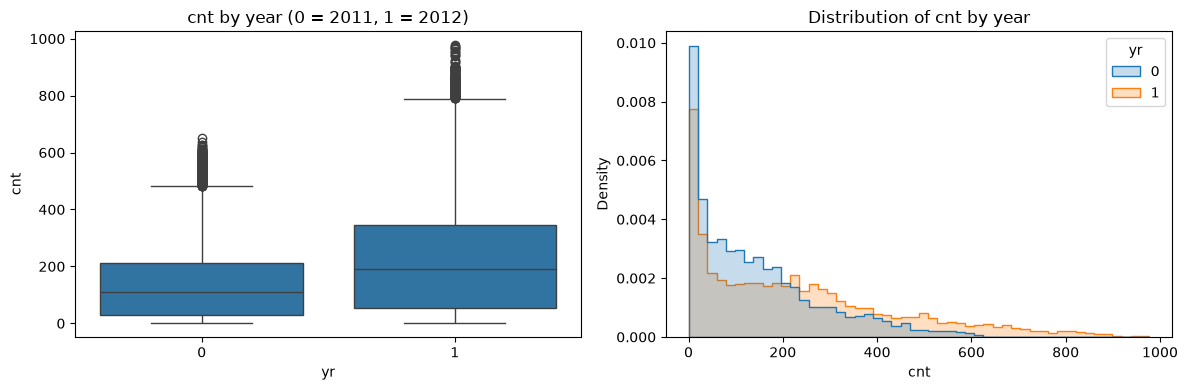

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x="yr", y="cnt", ax=axes[0])
axes[0].set_title("cnt by year (0 = 2011, 1 = 2012)")

sns.histplot(data=df, x="cnt", hue="yr", bins=50, stat="density",
             common_norm=False, element="step", ax=axes[1])
axes[1].set_title("Distribution of cnt by year")

plt.tight_layout()
plt.savefig("figures/year_shift_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [33]:
print(df.groupby("yr")[["temp", "hum", "windspeed"]].mean().round(3))
print(pd.crosstab(df["yr"], df["weathersit"], normalize="index").round(3))

     temp    hum  windspeed
yr                         
0   0.489  0.643      0.191
1   0.505  0.611      0.189
weathersit      1      2      3    4
yr                                  
0           0.653  0.257  0.090  0.0
1           0.660  0.266  0.073  0.0


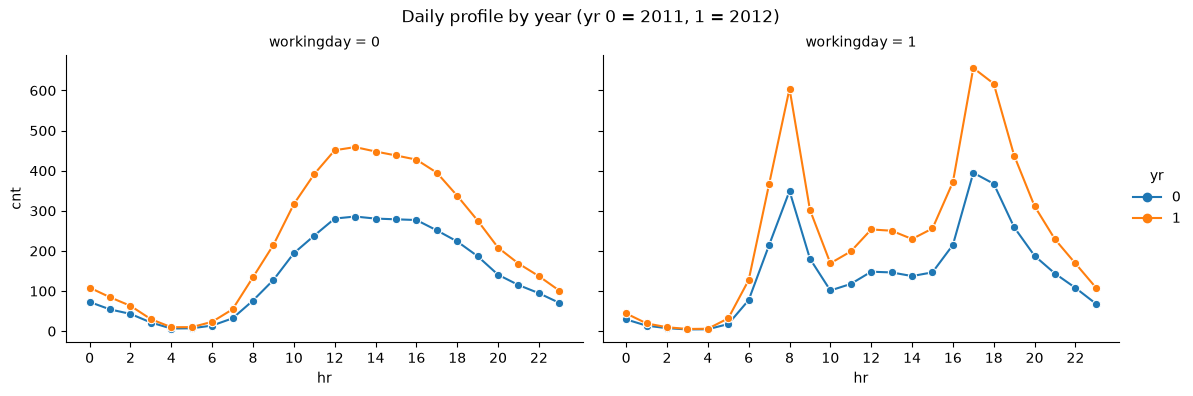

In [34]:
profile = df.groupby(["yr", "workingday", "hr"])["cnt"].mean().reset_index()

g = sns.relplot(data=profile, x="hr", y="cnt", hue="yr", col="workingday",
                kind="line", marker="o", height=3.8, aspect=1.5,
                palette=["tab:blue", "tab:orange"])
g.set(xticks=range(0, 24, 2))
g.fig.suptitle("Daily profile by year (yr 0 = 2011, 1 = 2012)", y=1.03)
g.savefig("figures/year_shift_hourly_profile.png", dpi=150, bbox_inches="tight")
plt.show()